<p style="text-align:center"><img src="images/08_web_gis.png" alt="Web and Cloud GIS" width="100%"></p>

# Cloud-Native Vectors: GeoParquet, FlatGeobuf and PMTiles

Vector data have their own cloud-native formats. A shapefile or a GeoJSON file must be read from
the beginning to find anything, which is fine on a laptop and slow over the internet. GeoParquet
stores features column by column in compressed row groups with statistics, so a reader can skip
most of the file; FlatGeobuf puts a spatial index at the front; PMTiles packs pre-cut map tiles
into one file. This notebook converts a large real dataset, every union (the smallest
administrative unit) of Bangladesh, to these formats, looks inside them, and measures how many
bytes each one transfers to answer the same query over HTTP.



### Learning objectives

1. Explain the limits of shapefiles and GeoJSON for large or remote data.
2. Write GeoParquet (with a bbox covering column and spatial sorting), FlatGeobuf, PMTiles,
   GeoPackage and GeoJSON Sequences, and compare their size and speed.
3. Read the row-group structure of a GeoParquet file and see how sorting enables skipping.
4. Query GeoParquet with bounding boxes, column selection and SQL (DuckDB).
5. Serve files over HTTP with range requests and measure what each format transfers.
6. Build and inspect a PMTiles vector-tile archive for web maps.



### Data

| Data | Source |
|---|---|
| Union boundaries of Bangladesh (admin level 4), 5,160 polygons, 7.8 million vertices, with division, district and upazila names | `Data/00_shared/vector_data/Bangladesh/Shapefiles/bd_union_GCS.shp` |
| Division boundaries of Bangladesh (admin level 1) | `Data/00_shared/vector_data/Bangladesh/Shapefiles/bd_division_GCS.shp` |



### Contents

1. Setup
2. Why not shapefiles and GeoJSON?
3. Writing cloud-native formats
4. Inside a GeoParquet file
5. Querying GeoParquet locally: bounding boxes, columns and SQL
6. Over the network: what does each format transfer?
7. PMTiles: vector tiles in one file
8. GeoJSON Sequences: streaming features
9. Choosing a format
10. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup: imports, Bangladesh shapefile paths, and a fresh output directory
%matplotlib inline
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import json
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from shapely.geometry import box

import geolattice
import geolattice.web as web
from geolattice.vector import (open_cloud_native_vector_data, read_geoparquet, write_flatgeobuf,
                          write_geoparquet, write_pmtiles)

# Working paths and the central Dhaka query box
plt.rcParams.update({"figure.dpi": 110})
DATA = Path("../../../Data")
BD = DATA / "00_shared" / "vector_data" / "Bangladesh" / "Shapefiles"
OUT = DATA / "00_shared" / "data_web_cloud_gis" / "08_02_outputs"
if OUT.exists():
    shutil.rmtree(OUT)
OUT.mkdir(parents=True)
DHAKA = (90.35, 23.70, 90.45, 23.82)          # central Dhaka, lon/lat
print("geolattice", geolattice.__version__, "| outputs:", OUT)


geolattice 0.3.11 | outputs: ../../../data/data_web_cloud_gis/08_02_outputs


In [2]:
# Load Bangladesh union and division polygons; time the shapefile read
t0 = time.perf_counter()
unions = gpd.read_file(BD / "bd_union_GCS.shp")
t_read_shp = time.perf_counter() - t0
divisions = gpd.read_file(BD / "bd_division_GCS.shp")
print(f"{len(unions):,} unions, {int(unions.geometry.count_coordinates().sum()):,} vertices, CRS {unions.crs}, "
      f"read in {t_read_shp:.2f} s")
unions[["ADM4_EN", "ADM3_EN", "ADM2_EN", "ADM1_EN", "ADM4_PCODE"]].head()


5,160 unions, 7,768,324 vertices, CRS EPSG:4326, read in 0.31 s


,ADM4_EN,ADM3_EN,ADM2_EN,ADM1_EN,ADM4_PCODE
0,Abaipur,Shailkupa,Jhenaidah,Khulna,BD40448010
1,Abdullahpur,Tongibari,Munshiganj,Dhaka,BD30599411
2,Abdullapur,Char Fasson,Bhola,Barisal,BD10092513
3,Abdullapur,Fatikchhari,Chittagong,Chittagong,BD20153311
4,Abdulpur,Kushtia Sadar,Kushtia,Khulna,BD40507916


## Why not shapefiles and GeoJSON?

The shapefile (1990s, Esri) is still the most common GIS file, but it is a bundle of separate
files, has a 2 GB limit per file, stores attributes in an old dBASE table with **10-character field
names**, has no compression, and keeps no spatial index unless extra index files are made. GeoJSON
is a single text file that every web tool reads, but it is large (coordinates are written as
text) and has to be parsed from start to end.

In [3]:
# Show shapefile sidecar sizes and the classic 10-character field-name limit
parts = sorted(BD.glob("bd_union_GCS.*"))
print(f"One shapefile = {len(parts)} files, {sum(p.stat().st_size for p in parts) / 1e6:.1f} MB:")
for p in parts:
    print(f"  {p.name:22s} {p.stat().st_size / 1e6:8.2f} MB")
long_names = [c for c in unions.columns if len(c) == 10]
print("Field names cut to 10 characters:", long_names)


One shapefile = 9 files, 128.7 MB:
  bd_union_GCS.cpg           0.00 MB
  bd_union_GCS.dbf           3.68 MB
  bd_union_GCS.prj           0.00 MB
  bd_union_GCS.sbn           0.05 MB
  bd_union_GCS.sbx           0.00 MB
  bd_union_GCS.shp         124.58 MB
  bd_union_GCS.shp.xml       0.35 MB
  bd_union_GCS.shx           0.04 MB
  bd_union_GCS.xml           0.00 MB
Field names cut to 10 characters: ['Shape_Leng', 'Shape_Area', 'ADM4_PCODE', 'ADM4ALT1EN', 'ADM4ALT2EN', 'ADM3_PCODE', 'ADM2_PCODE', 'ADM1_PCODE', 'ADM0_PCODE']


Field names such as `ADM4ALT1EN` and `ADM4ALT2EN` are abbreviations forced by the 10-character
limit (alternative English names 1 and 2). The modern formats below keep full names, typed columns
and one file per dataset.



## Writing cloud-native formats

We write the same 5,160 unions in seven ways and compare file size, write time and the time to
read the whole file back.

| Format | Layout | Spatial access |
|---|---|---|
| GeoJSON | Text, one document | None: parse everything |
| GeoJSON Sequence | Text, one feature per line | Streamable, no index |
| GeoPackage | SQLite database | R-tree index, but SQLite pages need many small reads remotely |
| FlatGeobuf | Binary rows (FlatBuffers) | Packed Hilbert R-tree at the start of the file |
| GeoParquet | Columnar, compressed row groups | Row-group statistics (bbox covering column) |
| PMTiles | Pre-cut vector tiles | Tile directory; for display, not analysis (Section 7) |

In [4]:
# Export unions to several formats and benchmark write/read size and speed
writers = {
    "GeoJSON":                  ("unions.geojson",          lambda p: unions.to_file(p, driver="GeoJSON")),
    "GeoJSON Sequence":         ("unions.geojsonl",         lambda p: unions.to_file(p, driver="GeoJSONSeq")),
    "GeoPackage":               ("unions.gpkg",             lambda p: unions.to_file(p, driver="GPKG", layer="unions")),
    "FlatGeobuf":               ("unions.fgb",              lambda p: write_flatgeobuf(p, unions)),
    "GeoParquet (WKB, zstd)":   ("unions.parquet",          lambda p: write_geoparquet(p, unions, row_group_size=256)),
    "GeoParquet (WKB, snappy)": ("unions_snappy.parquet",   lambda p: write_geoparquet(p, unions, compression="snappy", row_group_size=256)),
    "GeoParquet (GeoArrow, zstd)": ("unions_geoarrow.parquet", lambda p: write_geoparquet(p, unions, geometry_encoding="geoarrow", row_group_size=256)),
}
readers = {".geojson": gpd.read_file, ".geojsonl": gpd.read_file, ".gpkg": gpd.read_file, ".fgb": gpd.read_file,
           ".parquet": read_geoparquet}
# Time each writer/reader pair against the shapefile baseline
rows = [{"format": "Shapefile (input)", "MB": sum(p.stat().st_size for p in parts) / 1e6, "write s": np.nan, "read s": t_read_shp}]
for name, (fname, write) in writers.items():
    path = OUT / fname
    t0 = time.perf_counter(); write(path); t_write = time.perf_counter() - t0
    t0 = time.perf_counter(); back = readers[path.suffix](path); t_read = time.perf_counter() - t0
    assert len(back) == len(unions)
    rows.append({"format": name, "MB": path.stat().st_size / 1e6, "write s": t_write, "read s": t_read})
formats = pd.DataFrame(rows).set_index("format")
formats["vs. shapefile"] = (formats["MB"] / formats.loc["Shapefile (input)", "MB"]).round(2)
formats.round(2)


,MB,write s,read s,vs. shapefile
format,,,,
Shapefile (input),128.72,NaN,0.31,1.00
GeoJSON,343.06,11.78,5.74,2.67
GeoJSON Sequence,218.62,9.30,10.26,1.70
GeoPackage,129.80,0.45,0.19,1.01
FlatGeobuf,126.16,0.41,0.17,0.98
"GeoParquet (WKB, zstd)",103.19,0.65,0.18,0.80
"GeoParquet (WKB, snappy)",107.74,0.70,0.17,0.84
"GeoParquet (GeoArrow, zstd)",98.10,0.84,0.17,0.76


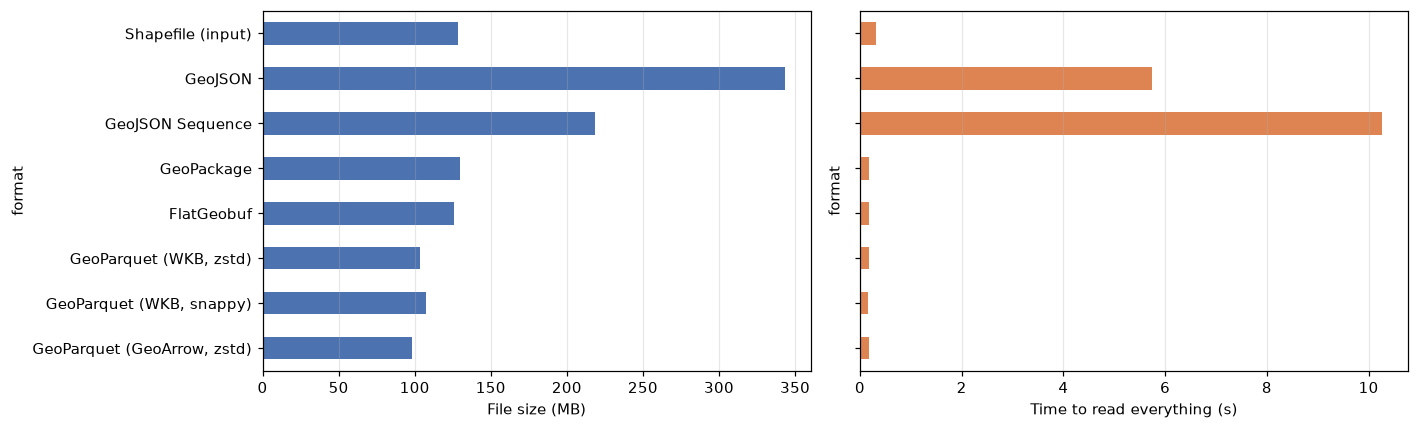

In [5]:
# Plot file size and full-read time across the formats just written
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
formats["MB"].plot.barh(ax=axes[0], color="#4c72b0"); axes[0].set_xlabel("File size (MB)")
formats["read s"].plot.barh(ax=axes[1], color="#dd8452"); axes[1].set_xlabel("Time to read everything (s)")
for a in axes:
    a.invert_yaxis(); a.grid(axis="x", alpha=0.3)
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()


The same 5,160 unions take very different space:

* **GeoJSON** is 343 MB, 2.7 times the shapefile, because every coordinate is written as text.
  It took about 12 s to write and 6 s to read.
* **GeoJSON Sequence** is smaller (219 MB, without indentation) but just as slow to parse.
* **GeoPackage and FlatGeobuf** are about the shapefile's size (130 and 126 MB) and read in under
  0.2 s.
* **GeoParquet** is the smallest: 103 MB with zstd compression, 108 MB with snappy, and 98 MB
  with the GeoArrow geometry encoding, which stores coordinates as plain numeric arrays rather
  than WKB blobs. It reads as fast as the binary formats.

Polygon coordinates are dense floating-point numbers that compress only modestly. For tables
with many attribute columns, GeoParquet's advantage is much larger.



## Inside a GeoParquet file

A GeoParquet file is a Parquet table with a `geo` metadata entry. Rows are grouped into **row
groups**; inside each group every column is stored and compressed separately, and the footer
records each column's minimum and maximum per group. GeoParquet 1.1 adds a **bbox covering column**
(`bbox.xmin`, `bbox.ymin`, `bbox.xmax`, `bbox.ymax` for every feature), so the footer statistics
describe the extent of each row group. `write_geoparquet` also sorts features along a Hilbert
curve, so that nearby features end up in the same row group.

In [6]:
# Inspect GeoParquet metadata: encoding, row groups, CRS, and columns
info = web.geoparquet_info(OUT / "unions.parquet")
display(pd.Series({k: info[k] for k in ["version", "primary_column", "encoding", "geometry_types", "covering",
                                        "num_rows", "num_row_groups"]}, name="unions.parquet").to_frame())
print("CRS:", info["crs"].name, "| columns:", ", ".join(info["columns"][:8]), "…")


,unions.parquet
version,1.1.0
primary_column,geometry
encoding,WKB
geometry_types,"[MultiPolygon, Polygon]"
covering,True
num_rows,5160
num_row_groups,21


CRS: WGS 84 | columns: Shape_Leng, Shape_Area, ADM4_EN, ADM4_PCODE, ADM4_REF, ADM4ALT1EN, ADM4ALT2EN, ADM3_EN …


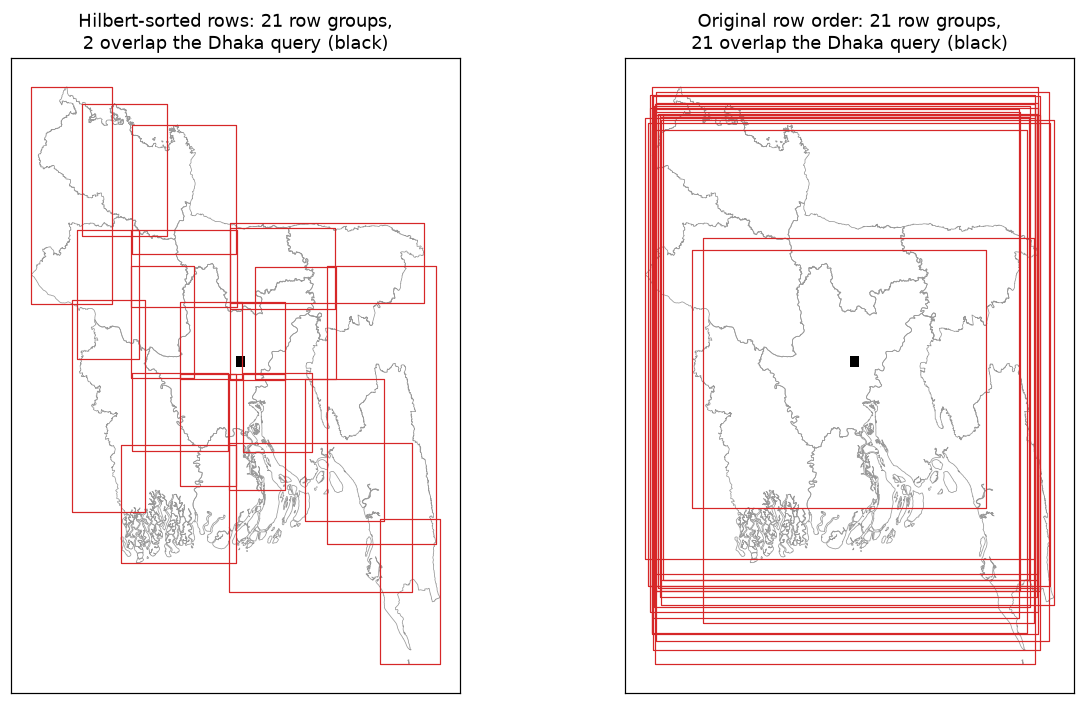

In [7]:
# Compare Hilbert-sorted vs unsorted row-group extents for a Dhaka bbox
# Build polygons from each row group's bbox statistics
def row_group_extents(path):
    meta = pq.ParquetFile(path).metadata
    out = []
    for g in range(meta.num_row_groups):
        rg = meta.row_group(g)
        stats = {rg.column(i).path_in_schema: rg.column(i).statistics for i in range(rg.num_columns)}
        out.append(box(stats["bbox.xmin"].min, stats["bbox.ymin"].min, stats["bbox.xmax"].max, stats["bbox.ymax"].max))
    return gpd.GeoDataFrame(geometry=out, crs=4326)

# Write an unsorted copy, then map which row groups hit Dhaka
write_geoparquet(OUT / "unions_unsorted.parquet", unions, sort_spatially=False, row_group_size=256)
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
hits = {}
for ax, (label, fname) in zip(axes, [("Hilbert-sorted rows", "unions.parquet"), ("Original row order", "unions_unsorted.parquet")]):
    ext = row_group_extents(OUT / fname)
    hits[label] = int(ext.intersects(box(*DHAKA)).sum())
    divisions.boundary.plot(ax=ax, color="0.6", lw=0.5)
    ext.boundary.plot(ax=ax, color="#d62728", lw=0.8)
    gpd.GeoSeries([box(*DHAKA)], crs=4326).plot(ax=ax, color="k")
    ax.set_title(f"{label}: {len(ext)} row groups,\n{hits[label]} overlap the Dhaka query (black)")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()


Each red box is the extent of one row group, read from the file's footer. With Hilbert-sorted rows
the 21 row groups each cover a compact region, and only **2** of them can contain features in
central Dhaka, so a reader can skip the other 19 using the statistics alone. With the original row
order (alphabetical by union name) every row group spans almost the whole country and all **21**
overlap the query, so nothing can be skipped. The covering column only pays off when the rows are
spatially sorted, which is why `write_geoparquet` sorts by default.



## Querying GeoParquet locally: bounding boxes, columns and SQL

`read_geoparquet` passes the bounding box to the Parquet reader, which uses the row-group
statistics to read only matching groups, then trims to the exact box. Because the file is columnar,
reading a few attribute columns is also cheap.

In [8]:
# Time a bbox query, an attribute-only read, and a full GeoParquet load
timings = {}
t0 = time.perf_counter(); dhaka = read_geoparquet(OUT / "unions.parquet", bbox=DHAKA); timings["bbox query (Dhaka)"] = time.perf_counter() - t0
t0 = time.perf_counter(); names = pq.read_table(OUT / "unions.parquet", columns=["ADM4_EN", "ADM2_EN", "ADM1_EN"]).to_pandas()
timings["three attribute columns, no geometry"] = time.perf_counter() - t0
t0 = time.perf_counter(); everything = read_geoparquet(OUT / "unions.parquet"); timings["everything"] = time.perf_counter() - t0
print(f"Dhaka query: {len(dhaka)} unions in {dhaka['ADM2_EN'].nunique()} districts "
      f"({', '.join(sorted(dhaka['ADM2_EN'].unique()))})")
pd.Series(timings, name="seconds").round(3).to_frame()


Dhaka query: 124 unions in 1 districts (Dhaka)


,seconds
bbox query (Dhaka),0.036
"three attribute columns, no geometry",0.004
everything,0.161


**SQL on files.** DuckDB is an in-process analytical database that queries Parquet files directly,
with no server and no import step. Its `spatial` extension adds PostGIS-style functions.
Notebook 08_03 goes further; here two questions show the idea: how many unions each division has,
and which unions intersect central Dhaka, using the bbox columns first and the exact geometry second.

In [9]:
# Aggregate and spatially filter GeoParquet with DuckDB + the spatial extension
import duckdb

con = duckdb.connect()
con.sql("INSTALL spatial; LOAD spatial; SET enable_progress_bar = false;")
src = (OUT / "unions.parquet").as_posix()
# Per-division counts and area from Parquet without loading into GeoPandas
per_division = con.sql(f'''
    SELECT ADM1_EN AS division, count(*) AS unions, count(DISTINCT ADM2_EN) AS districts,
           round(sum(ST_Area_Spheroid(ST_FlipCoordinates(geometry))) / 1e6) AS area_km2
    FROM read_parquet('{src}')
    GROUP BY division ORDER BY unions DESC''').df()
display(per_division)
# Bbox + geometry intersect for central Dhaka
xmin, ymin, xmax, ymax = DHAKA
in_dhaka = con.sql(f'''
    SELECT ADM4_EN AS union_name, ADM3_EN AS upazila
    FROM read_parquet('{src}')
    WHERE bbox.xmax >= {xmin} AND bbox.xmin <= {xmax} AND bbox.ymax >= {ymin} AND bbox.ymin <= {ymax}
      AND ST_Intersects(geometry, ST_MakeEnvelope({xmin}, {ymin}, {xmax}, {ymax}))''').df()
print(f"DuckDB: {len(in_dhaka)} unions intersect central Dhaka (GeoPandas: {len(dhaka)})")


,division,unions,districts,area_km2
0,Dhaka,1078,13,20383.0
1,Chittagong,1063,11,31147.0
2,Rajshahi,654,8,18229.0
3,Khulna,642,10,20750.0
4,Rangpur,565,8,16287.0
5,Barisal,401,6,10140.0
6,Sylhet,379,4,12373.0
7,Mymensingh,378,4,10545.0


DuckDB: 124 unions intersect central Dhaka (GeoPandas: 124)


Locally, the Dhaka query took 0.03 s against 0.16 s for the whole file. Reading three attribute
columns without geometry took 0.004 s: in a columnar file the geometry, almost all of the bytes,
is simply not touched.

DuckDB answered both questions straight from the file, with no import step:

* Dhaka division has the most unions (1,078 in 13 districts), but Chittagong has the largest area
  (about 31,000 km² on the WGS 84 ellipsoid).
* The same 124 unions intersect central Dhaka in DuckDB and GeoPandas.

`ST_FlipCoordinates` is needed because `ST_Area_Spheroid` expects latitude first.



## Over the network: what does each format transfer?

Locally every format is "fast enough". Over the internet the question is how many bytes and how
many requests a query needs. `web.static_server` serves our output folder over HTTP with range
requests, like an object store, and counts what it sends. We ask every format the same question,
**which unions intersect central Dhaka?**, and a second, attribute-only question.

In [10]:
# Serve files over HTTP and measure bytes transferred per format/tool for a Dhaka query
from osgeo import ogr, gdal
gdal.UseExceptions()

# Helper queries used by the remote timing loop below
def ogr_bbox_count(url):
    ds = ogr.Open(web.to_vsi_path(url))
    layer = ds.GetLayer(0)
    layer.SetSpatialFilterRect(*DHAKA)
    return sum(1 for _ in layer)

def reader_bbox_count(url):
    with open_cloud_native_vector_data(url) as ds:
        return len(ds.layer.to_dataframe(bbox=DHAKA))

def duckdb_bbox_count(url):
    return con.sql(f'''SELECT count(*) FROM read_parquet('{url}')
        WHERE bbox.xmax >= {xmin} AND bbox.xmin <= {xmax} AND bbox.ymax >= {ymin} AND bbox.ymin <= {ymax}
          AND ST_Intersects(geometry, ST_MakeEnvelope({xmin}, {ymin}, {xmax}, {ymax}))''').fetchone()[0]

# Local static server + cloud env; reset stats before each run
con.sql("INSTALL httpfs; LOAD httpfs;")
results = []
with web.static_server(OUT) as srv, web.cloud_env():
    def run(fmt, tool, query, fn, fname):
        srv.reset(); t0 = time.perf_counter(); n = fn(f"{srv.url}/{fname}")
        results.append({"format": fmt, "tool": tool, "query": query, "features": n, "requests": srv.stats["requests"],
                        "MB transferred": srv.stats["bytes"] / 1e6, "file MB": (OUT / fname).stat().st_size / 1e6,
                        "seconds": time.perf_counter() - t0})
    run("GeoJSON", "GDAL /vsicurl/", "Dhaka bbox", ogr_bbox_count, "unions.geojson")
    run("GeoPackage", "GDAL /vsicurl/", "Dhaka bbox", ogr_bbox_count, "unions.gpkg")
    run("FlatGeobuf", "geolattice reader (GDAL)", "Dhaka bbox", reader_bbox_count, "unions.fgb")
    run("GeoParquet", "read_geoparquet (PyArrow)", "Dhaka bbox", lambda u: len(read_geoparquet(u, bbox=DHAKA)), "unions.parquet")
    run("GeoParquet", "geolattice reader (PyArrow)", "Dhaka bbox", reader_bbox_count, "unions.parquet")
    run("GeoParquet", "DuckDB httpfs", "Dhaka bbox", duckdb_bbox_count, "unions.parquet")
    run("GeoParquet, unsorted", "DuckDB httpfs", "Dhaka bbox", duckdb_bbox_count, "unions_unsorted.parquet")
    run("GeoParquet", "DuckDB httpfs", "union names only",
        lambda u: len(con.sql(f"SELECT ADM4_EN FROM read_parquet('{u}')").fetchall()), "unions.parquet")
remote = pd.DataFrame(results)
remote["% of file"] = (remote["MB transferred"] / remote["file MB"] * 100).round(1)
remote.round(3).set_index(["format", "tool", "query"])


features  \
format               tool                      query                        
GeoJSON              GDAL /vsicurl/            Dhaka bbox             124   
GeoPackage           GDAL /vsicurl/            Dhaka bbox             124   
FlatGeobuf           geolattice reader (GDAL)       Dhaka bbox             124   
GeoParquet           read_geoparquet (PyArrow) Dhaka bbox             124   
                     geolattice reader (PyArrow)    Dhaka bbox             124   
                     DuckDB httpfs             Dhaka bbox             124   
GeoParquet, unsorted DuckDB httpfs             Dhaka bbox             124   
GeoParquet           DuckDB httpfs             union names only      5160   

                                                                 requests  \
format               tool                      query                        
GeoJSON              GDAL /vsicurl/            Dhaka bbox             337   
GeoPackage           GDAL /vsicurl/            Dhaka bbox              58   
FlatGeobuf           geolattice reader (GDAL)       Dhaka bbox              10   
GeoParquet           read_geoparquet (PyArrow) Dhaka bbox               7   
                     geolattice reader (PyArrow)    Dhaka bbox               6   
                     DuckDB httpfs             Dhaka bbox              11   
GeoParquet, unsorted DuckDB httpfs             Dhaka bbox              92   
GeoParquet           DuckDB httpfs             union names only        21   

                                                                 MB transferred  \
format               tool                      query                              
GeoJSON              GDAL /vsicurl/            Dhaka bbox               686.125   
GeoPackage           GDAL /vsicurl/            Dhaka bbox                 2.134   
FlatGeobuf           geolattice reader (GDAL)       Dhaka bbox                 0.721   
GeoParquet           read_geoparquet (PyArrow) Dhaka bbox                13.272   
                     geolattice reader (PyArrow)    Dhaka bbox                 8.094   
                     DuckDB httpfs             Dhaka bbox                 7.943   
GeoParquet, unsorted DuckDB httpfs             Dhaka bbox                52.550   
GeoParquet           DuckDB httpfs             union names only           0.039   

                                                                 file MB  \
format               tool                      query                       
GeoJSON              GDAL /vsicurl/            Dhaka bbox        343.063   
GeoPackage           GDAL /vsicurl/            Dhaka bbox        129.798   
FlatGeobuf           geolattice reader (GDAL)       Dhaka bbox        126.159   
GeoParquet           read_geoparquet (PyArrow) Dhaka bbox        103.195   
                     geolattice reader (PyArrow)    Dhaka bbox        103.195   
                     DuckDB httpfs             Dhaka bbox        103.195   
GeoParquet, unsorted DuckDB httpfs             Dhaka bbox        110.212   
GeoParquet           DuckDB httpfs             union names only  103.195   

                                                                 seconds  \
format               tool                      query                       
GeoJSON              GDAL /vsicurl/            Dhaka bbox          7.619   
GeoPackage           GDAL /vsicurl/            Dhaka bbox          0.106   
FlatGeobuf           geolattice reader (GDAL)       Dhaka bbox          0.063   
GeoParquet           read_geoparquet (PyArrow) Dhaka bbox          0.161   
                     geolattice reader (PyArrow)    Dhaka bbox          0.101   
                     DuckDB httpfs             Dhaka bbox          0.027   
GeoParquet, unsorted DuckDB httpfs             Dhaka bbox          1.256   
GeoParquet           DuckDB httpfs             union names only    1.255   

                                                                 % of file  
format               tool                  

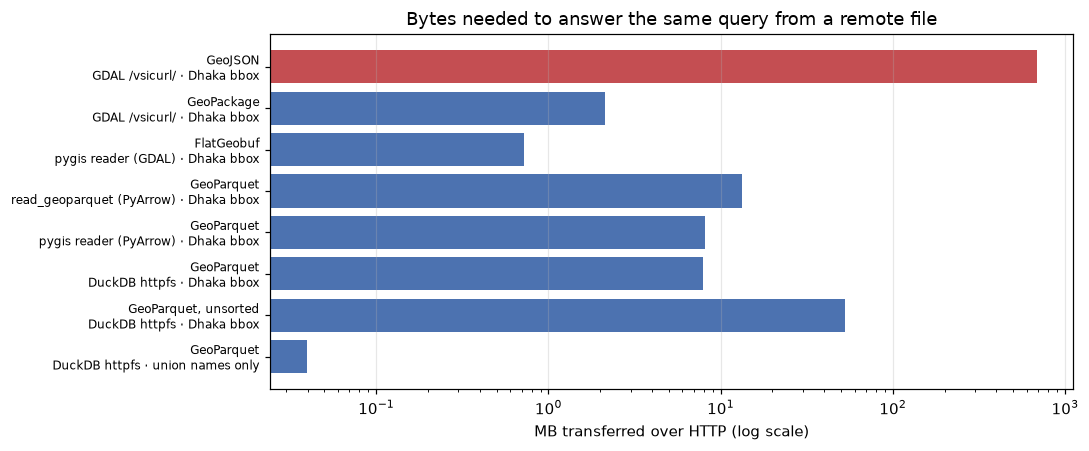

In [11]:
# Log-scale bar chart of HTTP bytes transferred for each remote query
fig, ax = plt.subplots(figsize=(10, 4.2))
labels = remote["format"] + "\n" + remote["tool"] + " · " + remote["query"]
ax.barh(labels, remote["MB transferred"], color=["#c44e52" if "GeoJSON" in f else "#4c72b0" for f in remote["format"]])
ax.set_xscale("log"); ax.set_xlabel("MB transferred over HTTP (log scale)")
ax.invert_yaxis(); ax.grid(axis="x", alpha=0.3); ax.tick_params(axis="y", labelsize=8)
ax.set_title("Bytes needed to answer the same query from a remote file")
plt.tight_layout(); plt.show()


All tools returned the same 124 unions, but the cost differed enormously:

| Format and tool | Transferred | Requests |
|---|---|---|
| GeoJSON | 686 MB, twice the file | 337 |
| GeoPackage | 2.1 MB | 58 |
| **FlatGeobuf** | **0.72 MB (0.6%)** | 10 |
| GeoParquet, sorted (DuckDB / GeoLattice reader) | about 8 MB | 6-11 |
| GeoParquet, sorted (`read_geoparquet`) | 13 MB | 7 |
| GeoParquet, unsorted | 53 MB | 92 |
| GeoParquet, names only (DuckDB) | 0.04 MB | 21 |

* **GeoJSON** has no index, and GDAL read it twice.
* **GeoPackage** works because its SQLite R-tree is read page by page.
* **FlatGeobuf** was the most efficient for a spatial window: its R-tree at the front points
  straight at the matching features.
* **Sorted GeoParquet** needed about 8 MB with DuckDB or the GeoLattice reader, because it skips row
  groups but reads whole ones. `read_geoparquet` read 13 MB because PyArrow fetches some
  additional columns. Unsorted, the same query cost 53 MB.
* **Attribute questions** are where GeoParquet shines: listing all 5,160 union names transferred
  only 39 kB, because the geometry column was never read.

Building this comparison exposed two bugs, now fixed in GeoLattice: the cloud-native reader could not
open GeoParquet over HTTP, and its bounding-box reads did not skip row groups (an earlier run of
this query transferred 2 GB).



## PMTiles: vector tiles in one file

Web maps do not draw raw features at every zoom; they draw **vector tiles**, small pre-cut,
simplified pieces of the data per `{z}/{x}/{y}` tile, in the Mapbox Vector Tile format. PMTiles
stores a whole tile pyramid in one file with a directory at the start, so a map in the browser
fetches each tile with a range request from static storage, with no tile server.

In [12]:
# Write a PMTiles archive of unions and summarize its header fields
t0 = time.perf_counter()
pm = write_pmtiles(OUT / "unions.pmtiles", unions[["ADM4_EN", "ADM3_EN", "ADM2_EN", "ADM1_EN", "geometry"]],
                   layer="unions", minzoom=4, maxzoom=11)
print(f"PMTiles written in {time.perf_counter() - t0:.1f} s, {Path(pm).stat().st_size / 1e6:.1f} MB")
with open_cloud_native_vector_data(pm) as ds:
    header = ds.details["header"]
    meta = ds.details["metadata"]
pd.Series({k: header[k] for k in ["version", "tile_type_name", "tile_compression_name", "min_zoom", "max_zoom",
                                  "addressed_tiles", "tile_contents", "tile_data_length", "root_length", "metadata_length"]},
          name="unions.pmtiles").to_frame()


PMTiles written in 13.8 s, 22.0 MB


,unions.pmtiles
version,3
tile_type_name,mvt
tile_compression_name,gzip
min_zoom,4
max_zoom,11
addressed_tiles,825
tile_contents,825
tile_data_length,22028071
root_length,2189
metadata_length,1867


Tile 11/1538/884 over central Dhaka: 28,309 bytes (gzip-compressed MVT)
Opening the remote archive: 4 request(s), 20,567 bytes; opening + one tile: 5 request(s), 48,876 bytes of a 22.0 MB file
Decoded layer CRS: EPSG:3857
Decoded zoom-11 features overlapping that tile: 131
Original unions intersecting the tile: 106; vertices in the tile's features: 24,054 (tiles) vs 17,543 (original, clipped)


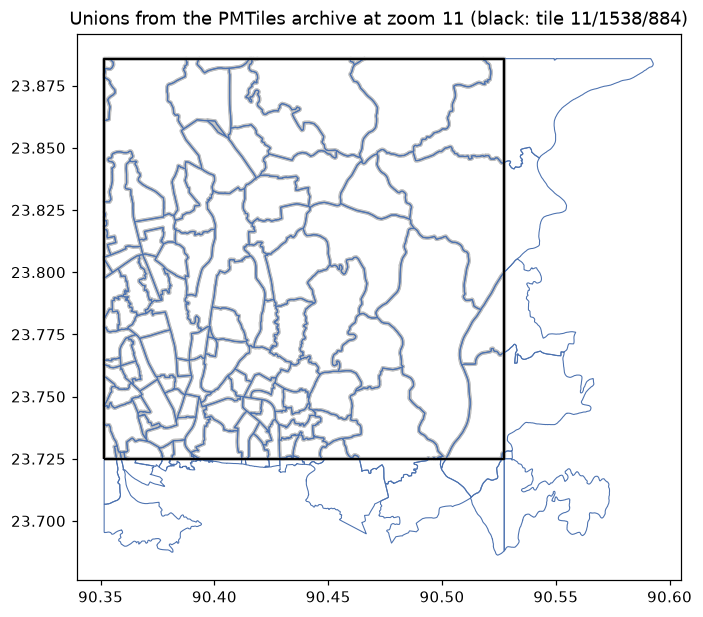

In [13]:
# Fetch one remote PMTiles tile over Dhaka, decode features, and compare to the source
z = 11
tile = web.lonlat_to_tile(90.40, 23.76, z)
# Open remotely and record requests needed for header + one tile
with web.static_server(OUT) as srv:
    srv.reset()
    with open_cloud_native_vector_data(f"{srv.url}/unions.pmtiles") as ds:
        opened = dict(srv.stats)
        raw = ds.read_tile(tile.z, tile.x, tile.y, decode=False)
    fetched = dict(srv.stats)
print(f"Tile {tile.z}/{tile.x}/{tile.y} over central Dhaka: {len(raw):,} bytes (gzip-compressed MVT)")
print(f"Opening the remote archive: {opened['requests']} request(s), {opened['bytes']:,} bytes; "
      f"opening + one tile: {fetched['requests']} request(s), {fetched['bytes']:,} bytes "
      f"of a {Path(pm).stat().st_size / 1e6:.1f} MB file")

# Decode the same tile locally and overlay against original polygons
with open_cloud_native_vector_data(pm, open_options={"ZOOM_LEVEL": str(z)}) as ds:
    print("Decoded layer CRS:", ds.layer.crs)                      # vector tiles are in Web Mercator
    tile_features = ds.layer.to_dataframe(bbox=web.tile_bounds(*tile, crs="EPSG:3857"))
tile_features = tile_features.set_crs(3857, allow_override=True).to_crs(4326)
print(f"Decoded zoom-{z} features overlapping that tile: {len(tile_features)}")
original = unions[unions.intersects(box(*web.tile_bounds(*tile)))]
print(f"Original unions intersecting the tile: {len(original)}; vertices in the tile's features: "
      f"{int(tile_features.geometry.count_coordinates().sum()):,} (tiles) vs "
      f"{int(original.clip(box(*web.tile_bounds(*tile))).geometry.count_coordinates().sum()):,} (original, clipped)")
# Original clipped geometries (grey) vs tile features (blue)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
original.clip(box(*web.tile_bounds(*tile))).boundary.plot(ax=ax, color="0.75", lw=2.5, label="original")
tile_features.boundary.plot(ax=ax, color="#4c72b0", lw=0.7, label="from the tile")
gpd.GeoSeries([box(*web.tile_bounds(*tile))], crs=4326).boundary.plot(ax=ax, color="k", lw=1.5)
ax.set_title(f"Unions from the PMTiles archive at zoom {z} (black: tile {tile.z}/{tile.x}/{tile.y})")
plt.tight_layout(); plt.show()


The PMTiles archive (zooms 4-11) is 22 MB: 825 tiles, gzip-compressed Mapbox Vector Tiles.

Opening it over HTTP read only the header, directory and metadata: 4 requests and 20 kB. Fetching
the zoom-11 tile over central Dhaka added one request of 28 kB. A web map works the same way,
touching only the tiles on screen. An earlier version of the GeoLattice reader decoded every tile on
open to count features, costing 8 MB; it now defers that count for remote archives.

The decoded tile gives 131 features against the 106 unions that intersect the tile. Two reasons:

* the reader returns features from the tiles touching the query box;
* each vector tile includes a buffer beyond its edge so that lines do not break at tile seams.

Tile geometries are also quantized to the tile's grid and simplified for their zoom, which is why
PMTiles is for display, not analysis.



## GeoJSON Sequences: streaming features

A GeoJSON Sequence (`.geojsonl`, newline-delimited GeoJSON) puts one complete feature on each line,
so a program can process features one at a time while reading, append new ones without rewriting
the file, and split work across machines by line. It is a good exchange and logging format for
streams of features, even though it has no index.

In [14]:
# Stream the first few GeoJSON Sequence features without loading the whole file
seq = OUT / "unions.geojsonl"
first = []
with open(seq) as handle:
    for line in handle:
        first.append(json.loads(line))
        if len(first) == 3:
            break
for f in first:
    print(f["properties"]["ADM4_EN"], "|", f["properties"]["ADM2_EN"], "|", f["geometry"]["type"],
          len(json.dumps(f)), "characters")
total_lines = sum(1 for _ in open(seq))
print(f"{total_lines:,} lines = {total_lines:,} features; we parsed only 3 of them")


Abaipur | Jhenaidah | Polygon 32285 characters
Abdullahpur | Munshiganj | Polygon 16479 characters
Abdullapur | Bhola | Polygon 12378 characters
5,160 lines = 5,160 features; we parsed only 3 of them


## Choosing a format

| Task | Best choice | Why |
|---|---|---|
| Analysis of large tables, data lakes, sharing with data-science tools | **GeoParquet** (sorted, with bbox covering) | Smallest, fastest, columnar; read by GeoPandas, DuckDB, Spark, BigQuery, R |
| Spatial windows from a remote file with GIS tools | **FlatGeobuf** | Spatial index at the start; streams with GDAL and in the browser |
| Showing data on a web map | **PMTiles** (vector tiles) | One static file, no tile server; simplified per zoom |
| Editing, multi-layer projects, desktop GIS | **GeoPackage** | Standard SQLite container, edits in place |
| Small datasets for web pages and APIs | **GeoJSON** | Universal, human-readable |
| Streams and logs of features | **GeoJSON Sequence** | One feature per line, append-only |
| Exchange with legacy software only | Shapefile | Supported everywhere, but avoid for new data |

## Summary and exercises

**Key ideas**

- Shapefiles and GeoJSON must be read whole; cloud-native formats are laid out so a reader can
  fetch only what a query needs.
- GeoParquet is columnar and compressed; with a bbox covering column and Hilbert-sorted rows, its
  row-group statistics let readers skip most of the file.
- FlatGeobuf's packed R-tree gives spatial windows over HTTP; PMTiles gives map tiles from one static file.
- DuckDB queries GeoParquet locally or over HTTP with SQL and no server.
- Always measure: requests and bytes, not just seconds, decide cloud performance.

**What we measured** (5,160 unions, 7.8 million vertices)

- File sizes: GeoJSON 343 MB, shapefile 129 MB, FlatGeobuf 126 MB, GeoParquet 98-108 MB.
- A remote Dhaka query transferred 686 MB from GeoJSON, 2.1 MB from GeoPackage, 0.72 MB from
  FlatGeobuf and about 8 MB from sorted GeoParquet; unsorted GeoParquet needed 53 MB.
- An attribute-only query on GeoParquet transferred 39 kB.
- A PMTiles archive opened remotely with 20 kB and served a tile with 28 kB more.

**Exercises**

1. Rewrite `unions.parquet` with `row_group_size=64` and `1024`. How do file size and the bytes
   transferred for the Dhaka query change?
2. Write the district layer (`bd_district_GCS.shp`) to FlatGeobuf without a spatial index
   (`spatial_index=False`) and repeat the remote query. What changes?
3. Use DuckDB over HTTP to compute the number of unions per district in Rajshahi division without
   downloading the geometry column. How many bytes are transferred?
4. Build a PMTiles archive with `maxzoom=13`. How do the size and the number of tiles grow?
5. Convert the US county layer (`Data/00_shared/vector_data/USA/US_COUNTY.shp`) to GeoParquet and query all
   counties of New York State with DuckDB.

**References**

- GeoParquet specification 1.1. https://geoparquet.org
- FlatGeobuf. https://flatgeobuf.org
- PMTiles specification v3. https://github.com/protomaps/PMTiles
- DuckDB spatial extension. https://duckdb.org/docs/extensions/spatial
- Cloud-Native Geospatial Foundation. *Cloud-Optimized Geospatial Formats Guide*. https://guide.cloudnativegeo.org